# Proyecto final: Predicción de enfermedad cardiovascular con Python, visualización y redes neuronales

Andres Hinojosa

* **Dataset:** Cardiovascular Disease dataset (Kaggle) https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset  

## Bloque 1. Planteamiento, carga e inspección de datos

### 1.A Planteamiento del problema

* **Problema:** las enfermedades cardiovasculares (ECV) son la principal causa de muerte en el mundo. Muchas personas no saben que están en riesgo hasta que tienen un evento (infarto, ACV).
* **Contexto:** el dataset tiene datos de un examen médico básico: edad, sexo, estatura, peso, presión arterial, colesterol, glucosa y hábitos (fumar, alcohol, actividad física).
* **Qué se predice:** si el paciente tiene o no enfermedad cardiovascular (`cardio`).
* **Usuarios de la predicción:** médicos de atención primaria y programas de prevención de una EPS o IPS, que necesitan priorizar a qué pacientes enviar a exámenes más completos (electrocardiograma, cardiología).
* **Impacto esperado:** detectar antes a los pacientes de mayor riesgo usando datos que ya se toman en cualquier consulta, sin exámenes costosos.

### 1.B Fuente del dataset

* **Enlace:** https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset
* **Autor:** Svetlana Ulianova (Kaggle)
* **Fecha:** publicado en 2019
* **Licencia:** Es un dataset público que se ha usado en muchos artículos académicos citando su enlace de Kaggle.
* **Por qué se eligió:** tiene 70.000 registros y 11 variables predictoras (5 numéricas y 6 categóricas), una variable objetivo clara y una descripción de sus columnas. Además tiene **errores reales** (presiones negativas o de 16.020 mm Hg, estaturas de 55 cm) que permiten demostrar el trabajo de limpieza. No es uno de los datasets prohibidos (no es el de diabetes del parcial).

### 1.C Librerías

In [ ]:
#Importar librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#Preparacion de datos
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

#Metricas
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

#Red neuronal
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

#Semilla para que los resultados se puedan repetir
semilla = 42
np.random.seed(semilla)
tf.keras.utils.set_random_seed(semilla)

I0000 00:00:1793190198.133972    4753 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793190198.226507    4753 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793190199.870947    4753 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### 1.D Carga del archivo con botón de carga

In [ ]:
from google.colab import files

#Boton para subir el csv descargado de Kaggle
archivo = files.upload()

#Se toma el nombre del archivo que se subio
nombre_archivo = list(archivo.keys())[0]
print("Archivo cargado:", nombre_archivo)

#Este archivo usa punto y coma (;) como separador
df = pd.read_csv(nombre_archivo, sep=";")

Archivo cargado: cardio_train.csv


### 1.E Primeras 10 filas y últimas 5

In [ ]:
#Primeras 10 filas
df.head(10)

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
5,8,21914,1,151,67.0,120,80,2,2,0,0,0,0
6,9,22113,1,157,93.0,130,80,3,1,0,0,1,0
7,12,22584,2,178,95.0,130,90,3,3,0,0,1,1
8,13,17668,1,158,71.0,110,70,1,1,0,0,1,0
9,14,19834,1,164,68.0,110,60,1,1,0,0,0,0


In [ ]:
#Ultimas 5 filas
df.tail(5)

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1
69999,99999,20540,1,170,72.0,120,80,2,1,0,0,1,0


### 1.F Número de registros y columnas

In [ ]:
print("Numero de registros:", df.shape[0])
print("Numero de columnas:", df.shape[1])
print("")
print("Nombres reales de las columnas:")
print(list(df.columns))

Numero de registros: 70000
Numero de columnas: 13

Nombres reales de las columnas:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


### 1.G Tipos de datos, nulos y duplicados

In [ ]:
#Tipo de dato de cada columna
for columna in df.columns:
    print(columna, "=", df[columna].dtype)

id = int64
age = int64
gender = int64
height = int64
weight = float64
ap_hi = int64
ap_lo = int64
cholesterol = int64
gluc = int64
smoke = int64
alco = int64
active = int64
cardio = int64


In [ ]:
#Valores nulos por columna
print("Nulos por columna:")
print(df.isnull().sum())
print("")

#Duplicados
print("Filas duplicadas completas:", df.duplicated().sum())
print("Duplicados sin contar el id:", df.drop(columns=["id"]).duplicated().sum())

Nulos por columna:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Filas duplicadas completas: 0
Duplicados sin contar el id: 24


**Resultado:** las 13 columnas son numéricas (`int64` y `float64`), aunque varias son categorías codificadas con números. No hay valores nulos. No hay filas duplicadas completas porque el `id` es distinto en cada fila, pero al quitar el `id` aparecen **24 filas duplicadas** (mismo paciente registrado dos veces).

### 1.H Variable objetivo

La variable objetivo es cardio porque es la columna que indica directamente si el paciente tiene enfermedad cardiovascular (1) o no (0)

### 1.I Diccionario de datos

Los nombres se verificaron con `df.columns`. Según la descripción del dataset, `age` viene en **días** y `gender` usa 1 y 2 (se comprueba más adelante cuál es hombre y cuál mujer).

In [ ]:
diccionario = pd.DataFrame({
    "Variable": ["id", "age", "gender", "height", "weight", "ap_hi", "ap_lo",
                 "cholesterol", "gluc", "smoke", "alco", "active", "cardio"],
    "Tipo": ["Identificador", "Numerica", "Categorica", "Numerica", "Numerica", "Numerica", "Numerica",
             "Categorica ordinal", "Categorica ordinal", "Categorica binaria", "Categorica binaria",
             "Categorica binaria", "Objetivo binaria"],
    "Unidad": ["-", "dias", "1 / 2", "cm", "kg", "mm Hg", "mm Hg",
               "1, 2, 3", "1, 2, 3", "0 / 1", "0 / 1", "0 / 1", "0 / 1"],
    "Significado": ["Numero del registro",
                    "Edad del paciente",
                    "Sexo del paciente",
                    "Estatura",
                    "Peso",
                    "Presion arterial sistolica (la alta)",
                    "Presion arterial diastolica (la baja)",
                    "Colesterol: 1 normal, 2 sobre lo normal, 3 muy sobre lo normal",
                    "Glucosa: 1 normal, 2 sobre lo normal, 3 muy sobre lo normal",
                    "Si fuma",
                    "Si consume alcohol",
                    "Si hace actividad fisica",
                    "Si tiene enfermedad cardiovascular"]
})
diccionario

,Variable,Tipo,Unidad,Significado
0,id,Identificador,-,Numero del registro
1,age,Numerica,dias,Edad del paciente
2,gender,Categorica,1 / 2,Sexo del paciente
3,height,Numerica,cm,Estatura
4,weight,Numerica,kg,Peso
5,ap_hi,Numerica,mm Hg,Presion arterial sistolica (la alta)
6,ap_lo,Numerica,mm Hg,Presion arterial diastolica (la baja)
7,cholesterol,Categorica ordinal,"1, 2, 3","Colesterol: 1 normal, 2 sobre lo normal, 3 muy..."
8,gluc,Categorica ordinal,"1, 2, 3","Glucosa: 1 normal, 2 sobre lo normal, 3 muy so..."
9,smoke,Categorica binaria,0 / 1,Si fuma


### Reto Bloque 1: función de informe de estructura y calidad

La función recibe cualquier DataFrame e imprime: tamaño, tipo de cada columna, % de nulos, duplicados, cardinalidad (valores únicos) de las categóricas y estadísticos descriptivos. En este dataset las categóricas vienen como números, por eso se consideran categóricas las columnas con pocos valores distintos.

In [ ]:
def informe_calidad(datos, max_categorias=10):
    print("INFORME DE ESTRUCTURA Y CALIDAD")
    print("Registros:", datos.shape[0])
    print("Columnas:", datos.shape[1])
    print("Filas duplicadas:", datos.duplicated().sum())
    print("")

    #Tabla con tipo, nulos y valores unicos de cada columna
    tabla = pd.DataFrame({
        "Tipo": datos.dtypes.astype(str),
        "Nulos": datos.isnull().sum(),
        "% Nulos": (datos.isnull().sum() / len(datos) * 100).round(2),
        "Valores unicos": datos.nunique()
    })
    print(tabla)
    print("")

    #Cardinalidad de las categoricas (columnas con pocos valores distintos)
    print("Categoricas (", max_categorias, "valores o menos ) y sus categorias:")
    for columna in datos.columns:
        if datos[columna].nunique() <= max_categorias:
            print("-", columna, ":", datos[columna].nunique(), "categorias ->", sorted(datos[columna].dropna().unique()))
    print("")

    #Estadisticos descriptivos
    print("Estadisticos descriptivos:")
    print(datos.describe().round(2).T)

informe_calidad(df)

INFORME DE ESTRUCTURA Y CALIDAD
Registros: 70000
Columnas: 13
Filas duplicadas: 0

                Tipo  Nulos  % Nulos  Valores unicos
id             int64      0      0.0           70000
age            int64      0      0.0            8076
gender         int64      0      0.0               2
height         int64      0      0.0             109
weight       float64      0      0.0             287
ap_hi          int64      0      0.0             153
ap_lo          int64      0      0.0             157
cholesterol    int64      0      0.0               3
gluc           int64      0      0.0               3
smoke          int64      0      0.0               2
alco           int64      0      0.0               2
active         int64      0      0.0               2
cardio         int64      0      0.0               2

Categoricas ( 10 valores o menos ) y sus categorias:
- gender : 2 categorias -> [np.int64(1), np.int64(2)]
- cholesterol : 3 categorias -> [np.int64(1), np.int64(2), np.int64

               count      mean       std      min       25%      50%  \
id           70000.0  49972.42  28851.30      0.0  25006.75  50001.5   
age          70000.0  19468.87   2467.25  10798.0  17664.00  19703.0   
gender       70000.0      1.35      0.48      1.0      1.00      1.0   
height       70000.0    164.36      8.21     55.0    159.00    165.0   
weight       70000.0     74.21     14.40     10.0     65.00     72.0   
ap_hi        70000.0    128.82    154.01   -150.0    120.00    120.0   
ap_lo        70000.0     96.63    188.47    -70.0     80.00     80.0   
cholesterol  70000.0      1.37      0.68      1.0      1.00      1.0   
gluc         70000.0      1.23      0.57      1.0      1.00      1.0   
smoke        70000.0      0.09      0.28      0.0      0.00      0.0   
alco         70000.0      0.05      0.23      0.0      0.00      0.0   
active       70000.0      0.80      0.40      0.0      1.00      1.0   
cardio       70000.0      0.50      0.50      0.0      0.00     

**Lectura del informe:** 70.000 registros y 13 columnas, sin nulos. Las categóricas tienen baja cardinalidad (2 o 3 categorías). Los descriptivos ya muestran errores: estatura mínima de 55 cm, peso mínimo de 10 kg, presión sistólica entre −150 y 16.020 y diastólica entre −70 y 11.000 mm Hg. Esos valores se tratan en el Bloque 2.

## Bloque 2. Limpieza, transformación e ingeniería de características

### 2.A Duplicados

In [ ]:
#Se quita el id: es un numero distinto en cada fila y esconde los duplicados
datos = df.drop(columns=["id"]).copy()

filas_antes = len(datos)
datos = datos.drop_duplicates()
print("Filas antes:", filas_antes)
print("Filas despues:", len(datos))
print("Filas eliminadas:", filas_antes - len(datos))

Filas antes: 70000
Filas despues: 69976
Filas eliminadas: 24


**Justificación:** se eliminan los 24 duplicados (0,03% de los datos). Un duplicado es el mismo paciente contado dos veces: pesa el doble y podría quedar una copia en entrenamiento y otra en prueba, haciendo que el modelo "ya conozca" a ese paciente e inflando las métricas. Como son tan pocos, quitarlos no afecta el tamaño del dataset.

### 2.B Transformaciones básicas: edad en años y sexo

In [ ]:
#La edad viene en dias, se pasa a años
datos["edad_anios"] = (datos["age"] / 365.25).round(1)
print(datos[["age", "edad_anios"]].head())
print("")

#Comprobar que es 1 y que es 2 en gender usando la estatura promedio
print("Estatura promedio por gender:")
print(datos.groupby("gender")["height"].mean().round(1))

     age  edad_anios
0  18393        50.4
1  20228        55.4
2  18857        51.6
3  17623        48.2
4  17474        47.8

Estatura promedio por gender:
gender
1    161.4
2    169.9
Name: height, dtype: float64


El código 1 tiene estatura promedio de 161,4 cm y el código 2 de 169,9 cm. Como los hombres en promedio son más altos, **1 = mujer y 2 = hombre**.

In [ ]:
#Label Encoding sencillo: mujer = 0, hombre = 1
datos["sexo"] = datos["gender"].map({1: 0, 2: 1})
datos = datos.drop(columns=["age", "gender"])
print(datos["sexo"].value_counts())

sexo
0    45509
1    24467
Name: count, dtype: int64


### 2.C Revisión de valores inválidos

No se eliminan filas automáticamente: se revisan reglas clínicas y, si un valor es imposible, solo **ese valor** se convierte en faltante (NaN). El resto de la información del paciente se conserva.

In [ ]:
print("Minimos y maximos de las medidas:")
for columna in ["height", "weight", "ap_hi", "ap_lo"]:
    print(columna, "| minimo:", datos[columna].min(), "| maximo:", datos[columna].max())
print("")

#Regla 1: presion sistolica fuera de 60 - 250 mm Hg (incluye negativos y valores como 16020)
sist_invalida = (datos["ap_hi"] < 60) | (datos["ap_hi"] > 250)

#Regla 2: presion diastolica fuera de 30 - 200 mm Hg
diast_invalida = (datos["ap_lo"] < 30) | (datos["ap_lo"] > 200)

#Regla 3: la sistolica siempre debe ser mayor que la diastolica
orden_invalido = datos["ap_hi"] <= datos["ap_lo"]

#Regla 4: estatura de adulto fuera de 120 - 220 cm
estatura_invalida = (datos["height"] < 120) | (datos["height"] > 220)

#Regla 5: peso de adulto menor a 35 kg
peso_invalido = datos["weight"] < 35

print("Sistolica fuera de rango:", sist_invalida.sum())
print("Diastolica fuera de rango:", diast_invalida.sum())
print("Sistolica <= diastolica:", orden_invalido.sum())
print("Estatura fuera de rango:", estatura_invalida.sum())
print("Peso menor a 35 kg:", peso_invalido.sum())

Minimos y maximos de las medidas:


height | minimo: 55 | maximo: 250
weight | minimo: 10.0 | maximo: 200.0
ap_hi | minimo: -150 | maximo: 16020
ap_lo | minimo: -70 | maximo: 11000

Sistolica fuera de rango: 228
Diastolica fuera de rango: 1006
Sistolica <= diastolica: 1236
Estatura fuera de rango: 53
Peso menor a 35 kg: 20


In [ ]:
#Ejemplos de presiones invalidas
datos.loc[sist_invalida | diast_invalida | orden_invalido, ["ap_hi", "ap_lo"]].head(10)

,ap_hi,ap_lo
228,160,1100
241,160,1000
260,140,800
329,160,1000
345,140,1000
473,150,1033
474,120,150
559,200,1000
567,14,90
613,140,1000


In [ ]:
#Solo el valor invalido se marca como faltante
datos.loc[sist_invalida | orden_invalido, "ap_hi"] = np.nan
datos.loc[diast_invalida | orden_invalido, "ap_lo"] = np.nan
datos.loc[estatura_invalida, "height"] = np.nan
datos.loc[peso_invalido, "weight"] = np.nan

print("Nulos despues de marcar los valores invalidos:")
print(datos.isnull().sum())
print("")
print("Filas con al menos un valor faltante:", datos.isnull().any(axis=1).sum(),
      "(", round(datos.isnull().any(axis=1).mean() * 100, 2), "% )")

Nulos despues de marcar los valores invalidos:
height           53
weight           20
ap_hi          1281
ap_lo          1289
cholesterol       0
gluc              0
smoke             0
alco              0
active            0
cardio            0
edad_anios        0
sexo              0
dtype: int64

Filas con al menos un valor faltante: 1390 ( 1.99 % )


**Hallazgos y decisión:**

* Hay presiones imposibles: negativas, sistólicas de 14 mm Hg (posible error de digitación de 140) o diastólicas de 1.000 a 11.000 mm Hg (posiblemente 100 o 110 con ceros de más). También 1.236 registros con la sistólica menor o igual que la diastólica.
* Hay 53 estaturas fuera de 120–220 cm y 20 pesos menores a 35 kg, que no corresponden a adultos.
* **No se elimina la fila**: solo el valor imposible se convierte en faltante. Así se conserva el resto de la información del paciente (edad, colesterol, hábitos). En total quedan 1.390 filas con algún faltante (1,99%).


### 2.D Valores faltantes: comparación de estrategias

El dataset original no tenía nulos; los faltantes aparecen al marcar los valores inválidos. Todas las variables con faltantes son **numéricas**, así que se comparan dos estrategias: **media** y **mediana**. Se toma `ap_hi` como ejemplo.

In [ ]:
columna = "ap_hi"

relleno_media = datos[columna].fillna(datos[columna].mean())
relleno_mediana = datos[columna].fillna(datos[columna].median())

comparacion = pd.DataFrame({
    "Sin rellenar": datos[columna].describe(),
    "Rellenar con media": relleno_media.describe(),
    "Rellenar con mediana": relleno_mediana.describe()
}).round(2)
print("Valor de la media:", round(datos[columna].mean(), 2))
print("Valor de la mediana:", datos[columna].median())
comparacion

Valor de la media: 126.68
Valor de la mediana: 120.0


,Sin rellenar,Rellenar con media,Rellenar con mediana
count,68695.00,69976.00,69976.00
mean,126.68,126.68,126.55
std,16.70,16.55,16.57
min,60.00,60.00,60.00
25%,120.00,120.00,120.00
50%,120.00,120.00,120.00
75%,140.00,140.00,140.00
max,240.00,240.00,240.00


**Comparación y decisión:** la media de `ap_hi` es 126,68 y la mediana 120. La media se deja afectar por los valores altos (hipertensos con 180–240 mm Hg), mientras que la mediana no. Por lo que se decide usar la media.



**Importante:** el relleno **no se hace aquí** sobre todos los datos. Se hace dentro del `Pipeline` con `SimpleImputer(strategy="median")`, calculando la mediana solo con entrenamiento (ver reto del Bloque 2).

### 2.E Valores atípicos: diagramas de caja y regla IQR

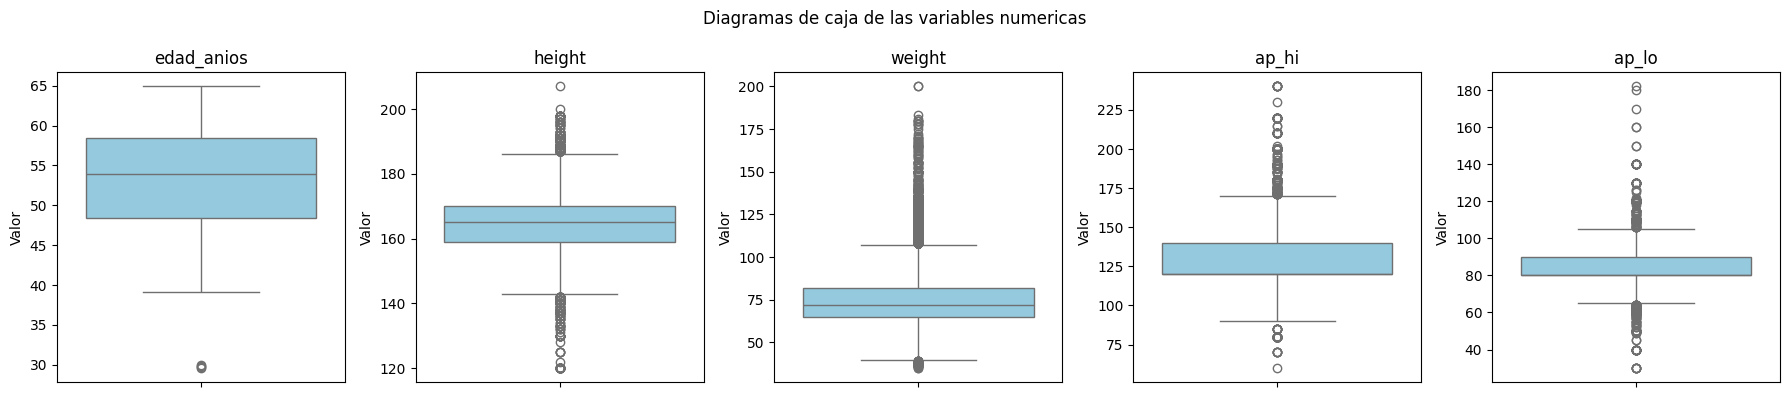

In [ ]:
numericas_originales = ["edad_anios", "height", "weight", "ap_hi", "ap_lo"]

fig, ejes = plt.subplots(1, 5, figsize=(18, 4))
for i in range(len(numericas_originales)):
    columna = numericas_originales[i]
    sns.boxplot(y=datos[columna], ax=ejes[i], color="skyblue")
    ejes[i].set_title(columna)
    ejes[i].set_ylabel("Valor")
plt.suptitle("Diagramas de caja de las variables numericas")
plt.tight_layout()
plt.show()

In [ ]:
#Conteo de atipicos con la regla del rango intercuartilico (IQR)
print("Variable | Limite inferior | Limite superior | Atipicos | %")
for columna in numericas_originales:
    q1 = datos[columna].quantile(0.25)
    q3 = datos[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    atipicos = ((datos[columna] < limite_inf) | (datos[columna] > limite_sup)).sum()
    print(columna, "|", round(limite_inf, 1), "|", round(limite_sup, 1), "|", atipicos, "|", round(atipicos / len(datos) * 100, 2))

Variable | Limite inferior | Limite superior | Atipicos | %
edad_anios | 33.4 | 73.4 | 4 | 0.01
height | 142.5 | 186.5 | 466 | 0.67
weight | 39.5 | 107.5 | 1799 | 2.57
ap_hi | 90.0 | 170.0 | 1013 | 1.45
ap_lo | 65.0 | 105.0 | 3517 | 5.03


**Decisión sobre atípicos:** no se eliminan. Después de quitar los valores imposibles (paso 2.C), lo que la regla IQR marca como atípico son valores raros pero **clínicamente posibles**: personas de 190 cm o 120 kg, presiones de 180 mm Hg (hipertensión grave) o diastólicas de 60 mm Hg. Muchos de estos pacientes son justamente los de mayor riesgo cardiovascular, así que quitarlos borraría información importante. Además `ap_lo` marca 5% como atípico solo porque casi todos tienen 80 mm Hg y la caja es muy estrecha.

### 2.F Codificación de variables categóricas

In [ ]:
for columna in ["sexo", "cholesterol", "gluc", "smoke", "alco", "active"]:
    print(columna, "->", sorted(datos[columna].unique()))

sexo -> [np.int64(0), np.int64(1)]
cholesterol -> [np.int64(1), np.int64(2), np.int64(3)]
gluc -> [np.int64(1), np.int64(2), np.int64(3)]
smoke -> [np.int64(0), np.int64(1)]
alco -> [np.int64(0), np.int64(1)]
active -> [np.int64(0), np.int64(1)]


* **`sexo`** (binaria): ya quedó en 0 y 1 con *Label Encoding* (`map`). Con dos categorías no hace falta One-Hot.
* **`cholesterol` y `gluc`** (ordinales): tienen un orden natural (normal < sobre lo normal < muy sobre lo normal). Se usa **codificación ordinal** 0, 1, 2 para que el número respete ese orden. One-Hot perdería el orden y crearía columnas de más.
* **`smoke`, `alco`, `active`** (binarias): ya vienen en 0 y 1, no necesitan cambio.

In [ ]:
#Codificacion ordinal: 1, 2, 3 -> 0, 1, 2
datos["cholesterol"] = datos["cholesterol"].map({1: 0, 2: 1, 3: 2})
datos["gluc"] = datos["gluc"].map({1: 0, 2: 1, 3: 2})
print(datos[["cholesterol", "gluc"]].head())

   cholesterol  gluc
0            0     0
1            2     0
2            2     0
3            0     0
4            0     0


### 2.G Ingeniería de características: dos variables nuevas

* **`imc`** = peso / estatura² (kg/m²). El peso y la estatura por separado dicen poco; el IMC indica sobrepeso y obesidad, un factor de riesgo cardiovascular conocido.
* **`presion_pulso`** = sistólica − diastólica (mm Hg). Una diferencia grande indica arterias más rígidas.

Se calculan fila por fila, así que no usan información de otros pacientes (no hay fuga de datos).

In [ ]:
datos["imc"] = (datos["weight"] / (datos["height"] / 100) ** 2).round(1)
datos["presion_pulso"] = datos["ap_hi"] - datos["ap_lo"]

print(datos[["height", "weight", "imc", "ap_hi", "ap_lo", "presion_pulso"]].head())
print("")
print(datos[["imc", "presion_pulso"]].describe().round(2))

   height  weight   imc  ap_hi  ap_lo  presion_pulso
0   168.0    62.0  22.0  110.0   80.0           30.0
1   156.0    85.0  34.9  140.0   90.0           50.0
2   165.0    64.0  23.5  130.0   70.0           60.0
3   169.0    82.0  28.7  150.0  100.0           50.0
4   156.0    56.0  23.0  100.0   60.0           40.0

            imc  presion_pulso
count  69903.00       68654.00
mean      27.49          45.37
std        5.28          11.68
min       12.30           5.00
25%       23.90          40.00
50%       26.40          40.00
75%       30.20          50.00
max      108.20         140.00


### 2.H Separar X e y, y Pipeline de preprocesamiento

In [ ]:
objetivo = "cardio"

variables_numericas = ["edad_anios", "height", "weight", "ap_hi", "ap_lo", "imc", "presion_pulso"]
variables_categoricas = ["sexo", "cholesterol", "gluc", "smoke", "alco", "active"]
variables_modelo = variables_numericas + variables_categoricas

X = datos[variables_modelo]
y = datos[objetivo]

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Variables predictoras:", len(variables_modelo))

Forma de X: (69976, 13)
Forma de y: (69976,)
Variables predictoras: 13


In [ ]:
#Pipeline: 1) rellenar faltantes con la mediana  2) escalar
#Se ajusta (fit) solo con los datos de entrenamiento, dentro de cada modelo
def crear_pipeline(modelo):
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", modelo)
    ])

El escalado sí corresponde para regresión logística y la red neuronal (son sensibles a la escala: la presión llega a 250 y `smoke` es 0 o 1). Para el árbol y el Random Forest no es necesario, pero no les hace daño, y así todos los modelos reciben la misma entrada.

### Reto Bloque 2: fuga de datos (*data leakage*)

La fuga de datos ocurre cuando el modelo usa, durante el entrenamiento, información que no tendría con pacientes nuevos. Las métricas salen mejores de lo que serían en la realidad.

**Ejemplo concreto en este dataset:** la mediana con la que se rellenan las presiones faltantes. Si se calcula con los 70.000 registros antes de dividir, la mediana incluye a los pacientes de prueba, y el modelo "ve" indirectamente esos datos. Lo mismo pasa con la media y la desviación del `StandardScaler`.

**Cómo se evitó:** no se rellenó ni se escaló nada antes de dividir. El `SimpleImputer` y el `StandardScaler` están dentro del `Pipeline`, que hace `fit` solo con entrenamiento y `transform` en prueba. En la validación cruzada el Pipeline se vuelve a ajustar en cada pliegue, así que el pliegue de validación tampoco se filtra. Abajo se demuestra que la mediana usada sale solo de entrenamiento.

## Bloque 3. Análisis exploratorio y visualización

Se crea una columna con texto solo para que las gráficas se lean mejor.

In [ ]:
datos["Diagnostico"] = datos[objetivo].map({0: "Sin ECV", 1: "Con ECV"})
colores = {"Sin ECV": "#2196F3", "Con ECV": "#F44336"}

print(datos[variables_numericas].describe().round(1).T)

                 count   mean   std    min    25%    50%    75%    max
edad_anios     69976.0   53.3   6.8   29.6   48.4   53.9   58.4   64.9
height         69923.0  164.4   7.9  120.0  159.0  165.0  170.0  207.0
weight         69956.0   74.2  14.4   35.0   65.0   72.0   82.0  200.0
ap_hi          68695.0  126.7  16.7   60.0  120.0  120.0  140.0  240.0
ap_lo          68687.0   81.3   9.5   30.0   80.0   80.0   90.0  182.0
imc            69903.0   27.5   5.3   12.3   23.9   26.4   30.2  108.2
presion_pulso  68654.0   45.4  11.7    5.0   40.0   40.0   50.0  140.0


### 3.A Distribución de la variable objetivo

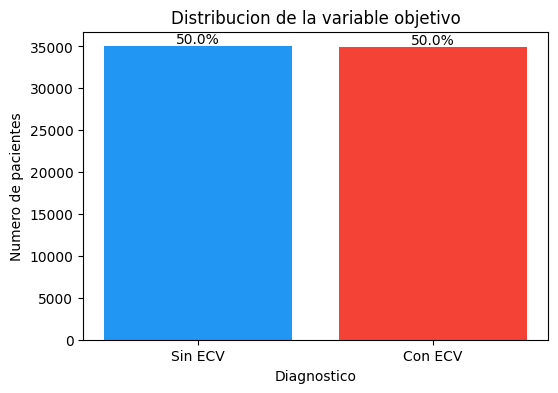

In [ ]:
conteo = datos["Diagnostico"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(conteo.index, conteo.values, color=[colores[c] for c in conteo.index])
for i in range(len(conteo)):
    porcentaje = round(conteo.values[i] / conteo.sum() * 100, 1)
    plt.text(i, conteo.values[i] + 300, str(porcentaje) + "%", ha="center")
plt.title("Distribucion de la variable objetivo")
plt.xlabel("Diagnostico")
plt.ylabel("Numero de pacientes")
plt.show()

* **Patrón:** las dos clases están prácticamente iguales: 50% con ECV y 50% sin ECV.
* **Información:** muestra que la variable objetivo está **balanceada**.
* **Limitación:** solo cuenta casos; no explica qué diferencia a los dos grupos. Además un 50% de enfermos es mucho más que en la población general, lo que indica que el dataset viene de pacientes que fueron a un examen médico.

### 3.B Histogramas de edad, IMC y presión sistólica

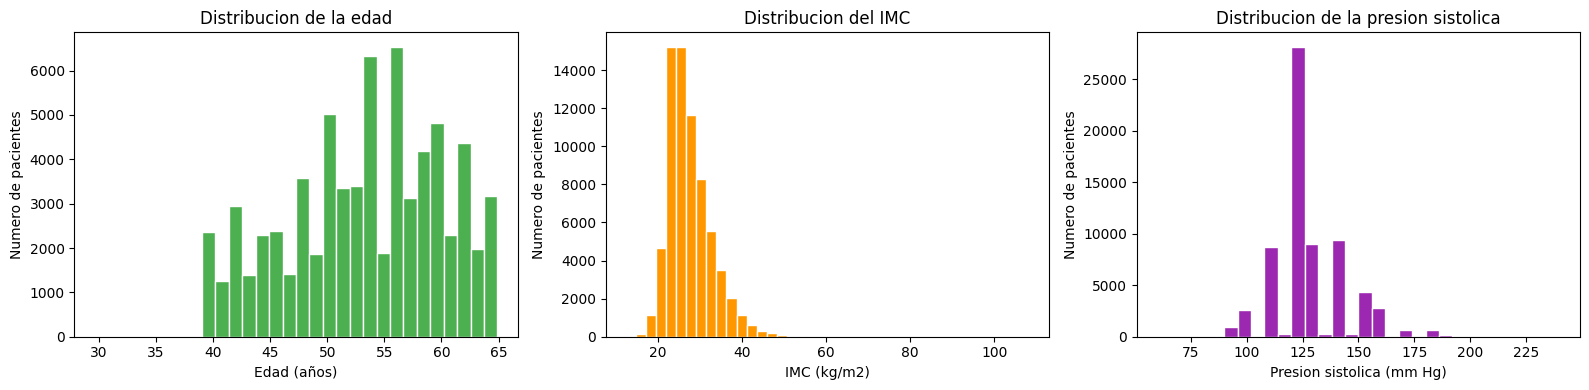

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

ejes[0].hist(datos["edad_anios"], bins=30, color="#4CAF50", edgecolor="white")
ejes[0].set_title("Distribucion de la edad")
ejes[0].set_xlabel("Edad (años)")
ejes[0].set_ylabel("Numero de pacientes")

ejes[1].hist(datos["imc"].dropna(), bins=40, color="#FF9800", edgecolor="white")
ejes[1].set_title("Distribucion del IMC")
ejes[1].set_xlabel("IMC (kg/m2)")
ejes[1].set_ylabel("Numero de pacientes")

ejes[2].hist(datos["ap_hi"].dropna(), bins=30, color="#9C27B0", edgecolor="white")
ejes[2].set_title("Distribucion de la presion sistolica")
ejes[2].set_xlabel("Presion sistolica (mm Hg)")
ejes[2].set_ylabel("Numero de pacientes")

plt.tight_layout()
plt.show()

* **Patrón:** la edad va de 30 a 65 años y la mayoría está entre 48 y 60 (mediana 54). El IMC tiene forma de campana con cola hacia la derecha: la mayoría está entre 24 y 30 (sobrepeso), con algunos casos de obesidad severa. La presión sistólica tiene picos en valores redondos (120, 130, 140), porque las mediciones se anotan redondeadas; 120 es el valor más frecuente.
* **Información:** muestra la forma, el rango y los valores típicos de cada variable.
* **Limitación:** no separa por diagnóstico y los picos en valores redondos muestran que la presión no es una medida muy precisa.

### 3.C Diagramas de caja: edad e IMC según diagnóstico

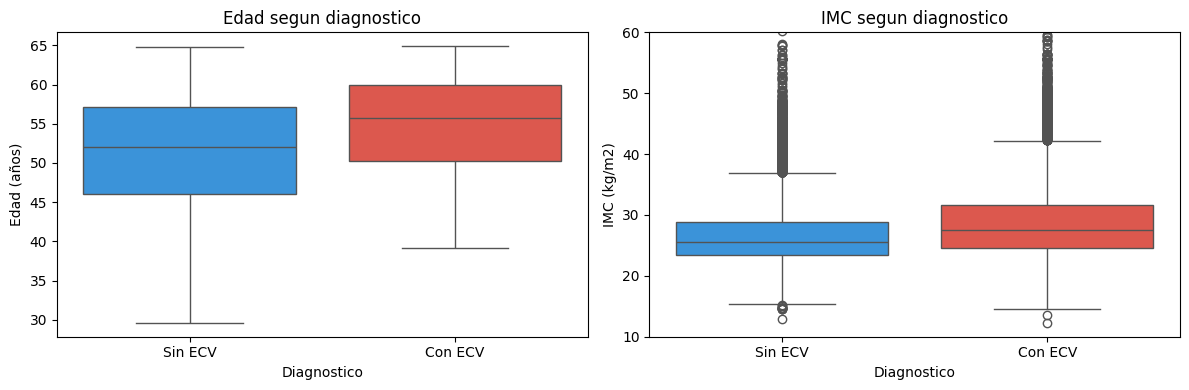

Mediana de cada variable numerica por grupo:
Diagnostico    Con ECV  Sin ECV
edad_anios        55.8     52.0
height           165.0    165.0
weight            75.0     70.0
ap_hi            130.0    120.0
ap_lo             80.0     80.0
imc               27.5     25.5
presion_pulso     50.0     40.0


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=datos, x="Diagnostico", y="edad_anios", hue="Diagnostico", palette=colores, legend=False, ax=ejes[0])
ejes[0].set_title("Edad segun diagnostico")
ejes[0].set_xlabel("Diagnostico")
ejes[0].set_ylabel("Edad (años)")

sns.boxplot(data=datos, x="Diagnostico", y="imc", hue="Diagnostico", palette=colores, legend=False, ax=ejes[1])
ejes[1].set_title("IMC segun diagnostico")
ejes[1].set_xlabel("Diagnostico")
ejes[1].set_ylabel("IMC (kg/m2)")
ejes[1].set_ylim(10, 60)

plt.tight_layout()
plt.show()

print("Mediana de cada variable numerica por grupo:")
print(datos.groupby("Diagnostico")[variables_numericas].median().round(1).T)

* **Patrón:** los pacientes con ECV son mayores (mediana 55,8 vs 52 años) y tienen IMC más alto (27,5 vs 25,5). La tabla de medianas muestra la misma tendencia en peso (75 vs 70 kg), presión sistólica (130 vs 120) y presión de pulso (50 vs 40). La estatura es igual en los dos grupos.
* **Información:** compara mediana, dispersión y atípicos de los dos grupos en una sola figura.
* **Limitación:** las cajas se superponen bastante, así que ninguna variable por sí sola separa a los grupos; y una diferencia de medianas no demuestra causalidad.

### 3.D Mapa de calor de correlaciones

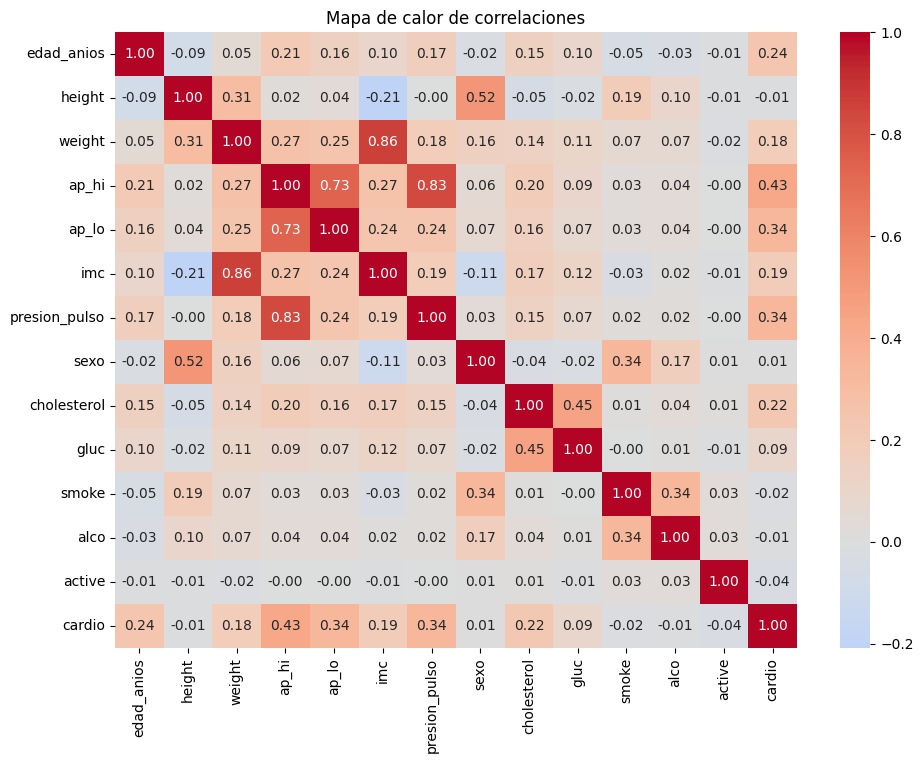

Correlacion con cardio
ap_hi            0.428
ap_lo            0.340
presion_pulso    0.337
edad_anios       0.238
cholesterol      0.221
imc              0.192
weight           0.182
gluc             0.089
sexo             0.008
alco            -0.007
height          -0.012
smoke           -0.016
active          -0.036
Name: cardio, dtype: float64


In [ ]:
correlacion = datos[variables_modelo + [objetivo]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Mapa de calor de correlaciones")
plt.show()

print("Correlacion con", objetivo)
print(correlacion[objetivo].drop(objetivo).sort_values(ascending=False).round(3))

* **Patrón:** la variable más relacionada con ECV es la presión sistólica (0,43), seguida de la diastólica (0,34), la presión de pulso (0,34, variable nueva), la edad (0,24), el colesterol (0,22) y el IMC (0,19, variable nueva). Sexo, alcohol, estatura y tabaquismo casi no tienen relación (cerca de 0). Entre predictoras, peso e IMC están muy relacionados, igual que las dos presiones entre sí.
* **Información:** indica qué variables tienen más relación lineal con el objetivo y cuáles se repiten información.
* **Limitación:** Pearson solo mide relaciones lineales; en variables binarias u ordinales es aproximado. Que fumar salga con correlación casi 0 (incluso negativa) no significa que fumar no haga daño: el dato es autorreportado y puede estar mal declarado.

### 3.E Dispersión: edad vs presión sistólica por diagnóstico

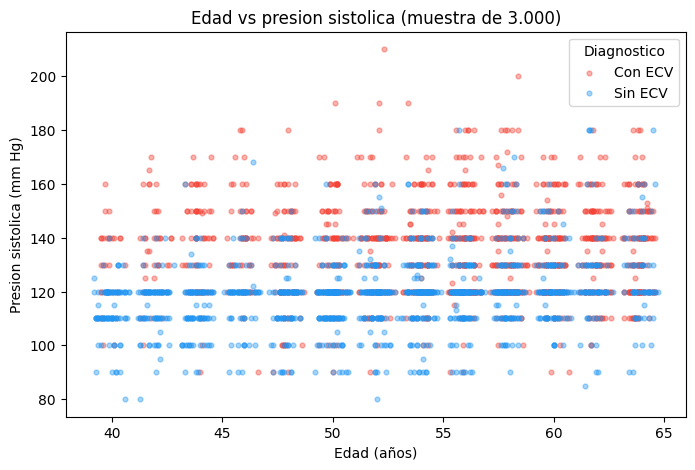

In [ ]:
#Con 70.000 pacientes los puntos se tapan; se usa una muestra de 3.000
muestra = datos.sample(3000, random_state=semilla)

plt.figure(figsize=(8, 5))
for etiqueta, grupo in muestra.groupby("Diagnostico"):
    plt.scatter(grupo["edad_anios"], grupo["ap_hi"], alpha=0.4, s=12, label=etiqueta, color=colores[etiqueta])
plt.title("Edad vs presion sistolica (muestra de 3.000)")
plt.xlabel("Edad (años)")
plt.ylabel("Presion sistolica (mm Hg)")
plt.legend(title="Diagnostico")
plt.show()

* **Patrón:** los puntos rojos (con ECV) predominan arriba (presión sistólica de 140 o más) y a la derecha (más edad). Por debajo de 120 mm Hg predominan los azules. En 120–130 mm Hg los dos grupos se mezclan mucho. Se ven "líneas" horizontales por los valores redondeados de presión.
* **Información:** muestra que al combinar edad y presión los grupos se separan mejor que con una sola variable.
* **Limitación:** es una muestra de 3.000 pacientes y solo se ven dos variables a la vez.

### 3.F Barras agrupadas: % con ECV según colesterol y glucosa

% con ECV por nivel:
                     Colesterol  Glucosa
Normal                     44.0     48.1
Sobre lo normal            60.2     59.3
Muy sobre lo normal        76.5     62.2


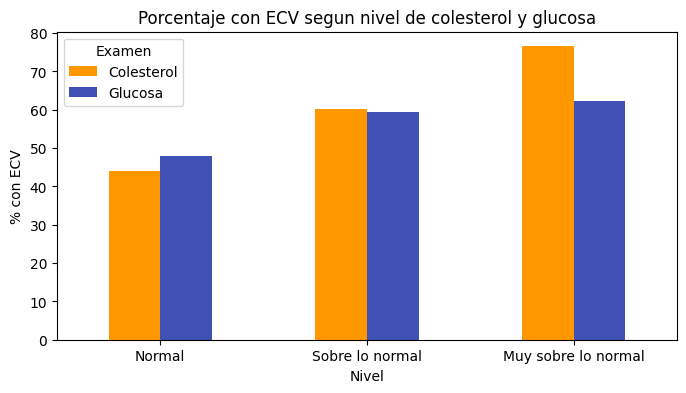

In [ ]:
porc_col = datos.groupby("cholesterol")[objetivo].mean() * 100
porc_glu = datos.groupby("gluc")[objetivo].mean() * 100

tabla_niveles = pd.DataFrame({"Colesterol": porc_col, "Glucosa": porc_glu})
tabla_niveles.index = ["Normal", "Sobre lo normal", "Muy sobre lo normal"]
print("% con ECV por nivel:")
print(tabla_niveles.round(1))

tabla_niveles.plot(kind="bar", figsize=(8, 4), color=["#FF9800", "#3F51B5"])
plt.title("Porcentaje con ECV segun nivel de colesterol y glucosa")
plt.xlabel("Nivel")
plt.ylabel("% con ECV")
plt.xticks(rotation=0)
plt.legend(title="Examen")
plt.show()

* **Patrón:** el porcentaje con ECV sube con el nivel de colesterol: 44% con colesterol normal, 60,2% sobre lo normal y 76,5% muy sobre lo normal. Con la glucosa sube menos (48,1% → 62,2%).
* **Información:** muestra que el colesterol alto es un factor de riesgo más fuerte que la glucosa alta en este dataset, y confirma que el orden de las categorías tiene sentido (justifica la codificación ordinal).
* **Limitación:** los grupos "muy sobre lo normal" tienen muchos menos pacientes que el normal, y la variable solo tiene 3 niveles, no el valor real del examen.

### 3.G Gráfica adicional: % con ECV por grupo de edad

grupo_edad
30-40    23.8
40-45    31.3
45-50    43.0
50-55    46.9
55-60    56.7
60-65    67.4
Name: cardio, dtype: float64


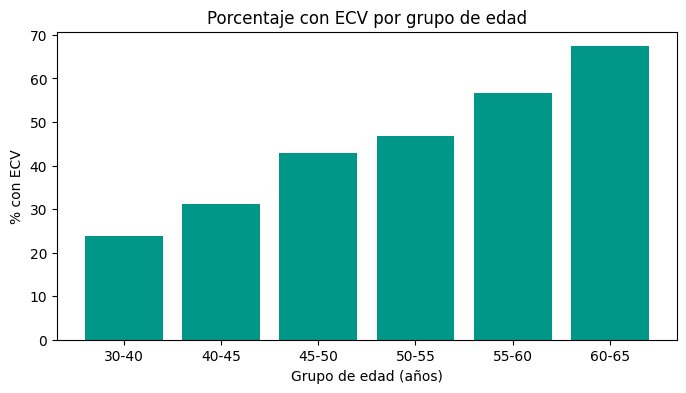

In [ ]:
datos["grupo_edad"] = pd.cut(datos["edad_anios"], bins=[29, 40, 45, 50, 55, 60, 65],
                             labels=["30-40", "40-45", "45-50", "50-55", "55-60", "60-65"])
porc_edad = datos.groupby("grupo_edad", observed=True)[objetivo].mean() * 100
print(porc_edad.round(1))

plt.figure(figsize=(8, 4))
plt.bar(porc_edad.index.astype(str), porc_edad.values, color="#009688")
plt.title("Porcentaje con ECV por grupo de edad")
plt.xlabel("Grupo de edad (años)")
plt.ylabel("% con ECV")
plt.show()

* **Patrón:** el porcentaje con ECV aumenta de forma constante con la edad: 23,8% entre 30 y 40 años hasta 67,4% entre 60 y 65 años.
* **Información:** es una forma muy fácil de explicar el efecto de la edad a alguien no técnico.
* **Limitación:** el grupo 30–40 tiene pocos pacientes y no se controlan otras variables (las personas mayores también tienen la presión más alta).

### Reto Bloque 3: análisis estadístico

**1. Prueba t:** ¿la edad promedio es distinta entre pacientes con y sin ECV?

In [ ]:
edad_con = datos.loc[datos[objetivo] == 1, "edad_anios"]
edad_sin = datos.loc[datos[objetivo] == 0, "edad_anios"]

prueba = stats.ttest_ind(edad_con, edad_sin)
print("Edad promedio con ECV:", round(edad_con.mean(), 2))
print("Edad promedio sin ECV:", round(edad_sin.mean(), 2))
print("Estadistico t:", round(prueba.statistic, 2))
print("Valor p:", prueba.pvalue)
print("")

#2. Correlacion de Pearson y Spearman entre edad y presion sistolica
sin_nulos = datos[["edad_anios", "ap_hi"]].dropna()
print("Pearson edad vs ap_hi:", round(stats.pearsonr(sin_nulos["edad_anios"], sin_nulos["ap_hi"])[0], 3))
print("Spearman edad vs ap_hi:", round(stats.spearmanr(sin_nulos["edad_anios"], sin_nulos["ap_hi"])[0], 3))
print("")

#3. Balance de clases
print("Proporcion de clases:")
print(datos[objetivo].value_counts(normalize=True).round(3))

Edad promedio con ECV: 54.91
Edad promedio sin ECV: 51.69
Estadistico t: 64.87
Valor p: 0.0

Pearson edad vs ap_hi: 0.209
Spearman edad vs ap_hi: 0.223

Proporcion de clases:
cardio
0    0.5
1    0.5
Name: proportion, dtype: float64


**Prueba t:** la edad promedio es 54,91 años con ECV y 51,69 sin ECV. El valor p es prácticamente 0 (menor a 0,05), así que la diferencia **es estadísticamente significativa**: no se debe al azar. Esto respalda lo que se vio en el boxplot y en la gráfica por grupos de edad.

**Pearson y Spearman (edad vs presión sistólica):** 0,209 y 0,223. Hay una relación positiva débil: a más edad, algo más de presión. Spearman sale un poco mayor porque mide relaciones que aumentan aunque no sean una línea recta, y no se afecta tanto por los valores redondeados.

**Correlación vs causalidad:** que la edad y la ECV estén relacionadas no prueba que una cause la otra directamente. La edad se relaciona con la presión, y la presión con la ECV; parte del efecto de la edad puede venir de la presión. Para hablar de causalidad se necesitarían estudios controlados, no solo datos observados.

**Balance de clases:** la variable objetivo está **balanceada** (50% / 50%). Por eso el accuracy sí es una métrica útil aquí (un modelo que siempre diga "sin ECV" solo tendría 50%), y no hace falta usar pesos de clase. Aun así se reportan precision, recall, F1 y AUC.

## Bloque 4. Modelos tradicionales de predicción

### 4.A División 80/20 estratificada

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=semilla, stratify=y)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("% con ECV en entrenamiento:", round(y_train.mean() * 100, 2))
print("% con ECV en prueba:", round(y_test.mean() * 100, 2))

Entrenamiento: (55980, 13)
Prueba: (13996, 13)
% con ECV en entrenamiento: 49.98
% con ECV en prueba: 49.98


In [ ]:
#Demostracion de que el relleno usa solo entrenamiento
print("Mediana de ap_hi con TODOS los datos:", X["ap_hi"].median())
print("Mediana de ap_hi solo con ENTRENAMIENTO:", X_train["ap_hi"].median())
print("Mediana de height con TODOS los datos:", X["height"].median())
print("Mediana de height solo con ENTRENAMIENTO:", X_train["height"].median())

Mediana de ap_hi con TODOS los datos: 120.0
Mediana de ap_hi solo con ENTRENAMIENTO: 120.0
Mediana de height con TODOS los datos: 165.0
Mediana de height solo con ENTRENAMIENTO: 165.0


### 4.B Tres modelos y validación cruzada (k = 5)

* **Regresión logística:** modelo base, sencillo e interpretable.
* **Árbol de decisión:** reglas fáciles de explicar.
* **Random Forest:** muchos árboles juntos; suele ser más preciso.

Métrica principal: **F1-score**, porque equilibra precisión y recall (encontrar enfermos sin demasiadas falsas alarmas).

In [ ]:
modelos = {
    "Regresion logistica": LogisticRegression(max_iter=1000, random_state=semilla),
    "Arbol de decision": DecisionTreeClassifier(max_depth=5, random_state=semilla),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=semilla, n_jobs=-1)
}

filas_cv = []
for nombre in modelos:
    pipe = crear_pipeline(modelos[nombre])
    puntajes = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1")
    filas_cv.append({"Modelo": nombre, "F1 promedio": puntajes.mean(), "Desviacion": puntajes.std()})
    print(nombre, "-> F1 en cada pliegue:", puntajes.round(3))

tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo").round(4)
tabla_cv

Regresion logistica -> F1 en cada pliegue: [0.708 0.711 0.703 0.708 0.707]


Arbol de decision -> F1 en cada pliegue: [0.704 0.705 0.688 0.7   0.703]


Random Forest -> F1 en cada pliegue: [0.71  0.713 0.703 0.713 0.711]


,F1 promedio,Desviacion
Modelo,,
Regresion logistica,0.7073,0.0025
Arbol de decision,0.7000,0.0061
Random Forest,0.7100,0.0036


**Resultado:** los tres modelos quedan muy cerca: Random Forest 0,710, regresión logística 0,707 y árbol 0,700 de F1 promedio. Las desviaciones son muy pequeñas (menos de 0,01), lo que indica que los modelos son **estables**: dan casi el mismo resultado sin importar qué pliegue se use para validar.

### 4.C Optimización de hiperparámetros con GridSearchCV (árbol de decisión)

In [ ]:
parametros = {
    "modelo__max_depth": [3, 5, 7, 9],
    "modelo__min_samples_leaf": [1, 20, 50]
}

busqueda = GridSearchCV(crear_pipeline(DecisionTreeClassifier(random_state=semilla)),
                        parametros, cv=5, scoring="f1")
busqueda.fit(X_train, y_train)

print("Mejores parametros:", busqueda.best_params_)
print("Mejor F1 en validacion cruzada:", round(busqueda.best_score_, 4))

Mejores parametros: {'modelo__max_depth': 9, 'modelo__min_samples_leaf': 50}
Mejor F1 en validacion cruzada: 0.7144


El GridSearchCV probó 12 combinaciones (4 profundidades × 3 tamaños de hoja) con validación cruzada de 5 pliegues. La mejor fue `max_depth=9` y `min_samples_leaf=50`, con F1 de 0,714, mejor que el árbol inicial (0,700 con profundidad 5). Pedir al menos 50 pacientes por hoja evita que el árbol cree reglas para casos muy particulares (sobreajuste).

### 4.D Entrenamiento final y evaluación en prueba

In [ ]:
def evaluar_modelo(nombre, y_real, y_pred, y_prob):
    resultado = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred),
        "Recall": recall_score(y_real, y_pred),
        "F1-score": f1_score(y_real, y_pred),
        "AUC": roc_auc_score(y_real, y_prob)
    }

    matriz = confusion_matrix(y_real, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Pred: Sin ECV", "Pred: Con ECV"],
                yticklabels=["Real: Sin ECV", "Real: Con ECV"])
    plt.title("Matriz de confusion - " + nombre)
    plt.xlabel("Prediccion")
    plt.ylabel("Valor real")
    plt.show()

    print("Verdaderos negativos:", matriz[0][0], "| Falsos positivos:", matriz[0][1])
    print("Falsos negativos:", matriz[1][0], "| Verdaderos positivos:", matriz[1][1])
    return resultado

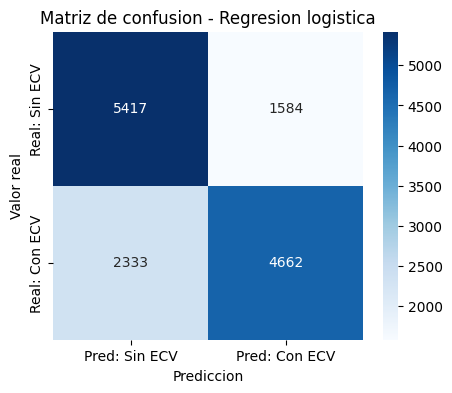

Verdaderos negativos: 5417 | Falsos positivos: 1584
Falsos negativos: 2333 | Verdaderos positivos: 4662


In [ ]:
#Modelo 1: regresion logistica
pipe_log = crear_pipeline(LogisticRegression(max_iter=1000, random_state=semilla))
pipe_log.fit(X_train, y_train)
prob_log = pipe_log.predict_proba(X_test)[:, 1]
resultado_log = evaluar_modelo("Regresion logistica", y_test, pipe_log.predict(X_test), prob_log)

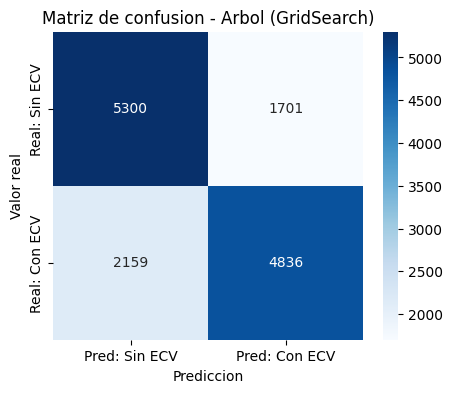

Verdaderos negativos: 5300 | Falsos positivos: 1701
Falsos negativos: 2159 | Verdaderos positivos: 4836


In [ ]:
#Modelo 2: arbol de decision con los mejores parametros del GridSearchCV
pipe_arbol = busqueda.best_estimator_
prob_arbol = pipe_arbol.predict_proba(X_test)[:, 1]
resultado_arbol = evaluar_modelo("Arbol (GridSearch)", y_test, pipe_arbol.predict(X_test), prob_arbol)

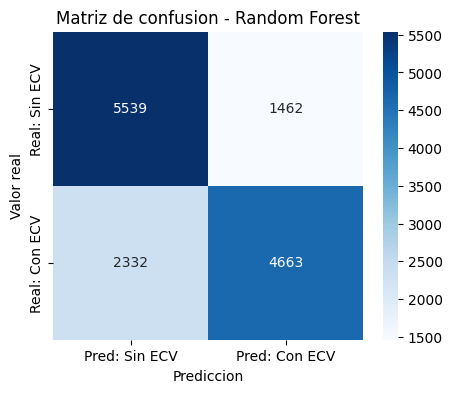

Verdaderos negativos: 5539 | Falsos positivos: 1462
Falsos negativos: 2332 | Verdaderos positivos: 4663


In [ ]:
#Modelo 3: Random Forest
pipe_rf = crear_pipeline(RandomForestClassifier(n_estimators=100, max_depth=10, random_state=semilla, n_jobs=-1))
pipe_rf.fit(X_train, y_train)
prob_rf = pipe_rf.predict_proba(X_test)[:, 1]
resultado_rf = evaluar_modelo("Random Forest", y_test, pipe_rf.predict(X_test), prob_rf)

### 4.E Curva ROC y tabla comparativa

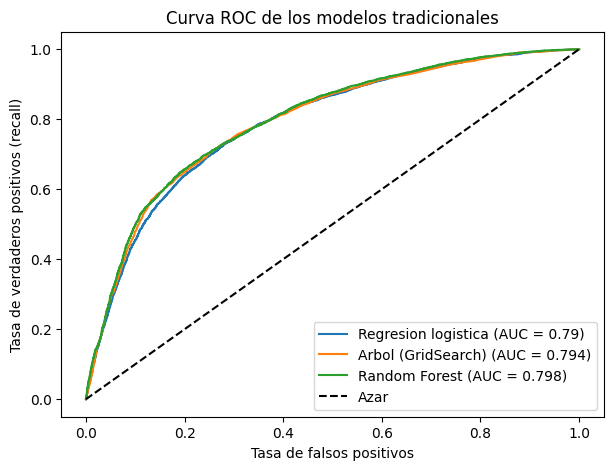

,Accuracy,Precision,Recall,F1-score,AUC
Modelo,,,,,
Regresion logistica,0.720,0.746,0.666,0.704,0.790
Arbol (GridSearch),0.724,0.740,0.691,0.715,0.794
Random Forest,0.729,0.761,0.667,0.711,0.798


In [ ]:
plt.figure(figsize=(7, 5))
for nombre, prob in [("Regresion logistica", prob_log), ("Arbol (GridSearch)", prob_arbol), ("Random Forest", prob_rf)]:
    fpr, tpr, umbrales = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=nombre + " (AUC = " + str(round(roc_auc_score(y_test, prob), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.title("Curva ROC de los modelos tradicionales")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.legend()
plt.show()

tabla_modelos = pd.DataFrame([resultado_log, resultado_arbol, resultado_rf]).set_index("Modelo").round(3)
tabla_modelos

### 4.F Importancia de variables

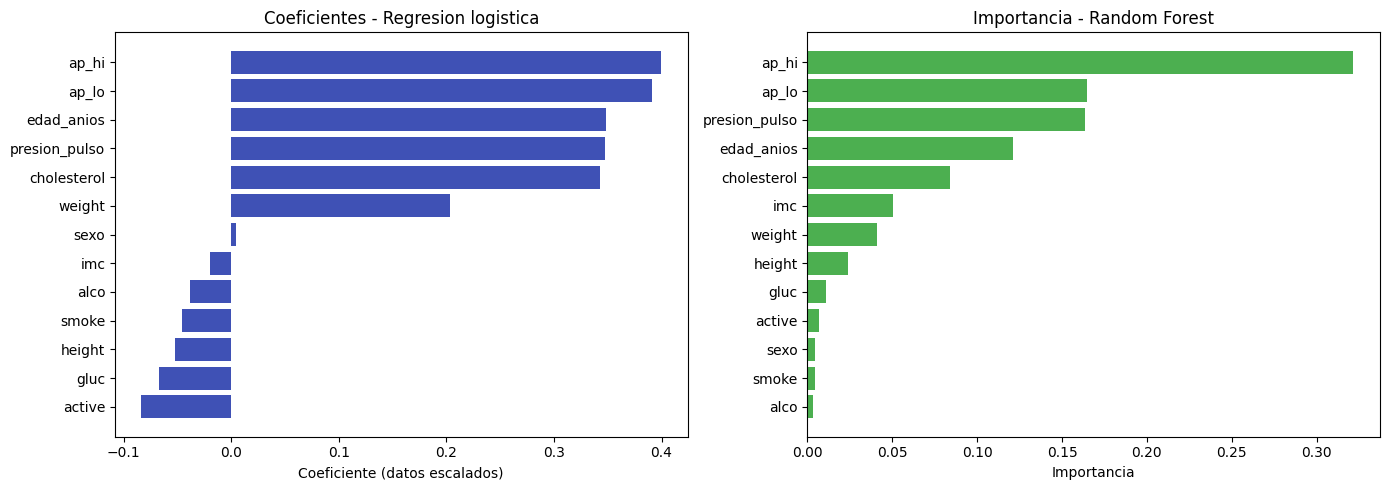

In [ ]:
coeficientes = pd.Series(pipe_log.named_steps["modelo"].coef_[0], index=variables_modelo).sort_values()
importancia_rf = pd.Series(pipe_rf.named_steps["modelo"].feature_importances_, index=variables_modelo).sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
ejes[0].barh(coeficientes.index, coeficientes.values, color="#3F51B5")
ejes[0].set_title("Coeficientes - Regresion logistica")
ejes[0].set_xlabel("Coeficiente (datos escalados)")

ejes[1].barh(importancia_rf.index, importancia_rf.values, color="#4CAF50")
ejes[1].set_title("Importancia - Random Forest")
ejes[1].set_xlabel("Importancia")
plt.tight_layout()
plt.show()

**Importancia de variables:** en los dos modelos la **presión sistólica** (`ap_hi`) es la variable más importante, seguida de la diastólica, la presión de pulso (variable nueva), la edad y el colesterol. En la regresión logística todas esas empujan hacia ECV, y `active` empuja en sentido contrario (hacer actividad física reduce el riesgo). La glucosa y el IMC salen con coeficiente negativo pequeño porque repiten información del colesterol y del peso (están muy relacionadas entre sí), no porque protejan. Sexo, alcohol y tabaquismo casi no aportan en ningún modelo.

Esto **coincide con el análisis exploratorio**: en el mapa de calor la presión sistólica era la variable más correlacionada (0,43), seguida de las otras presiones, la edad y el colesterol; y sexo, estatura, alcohol y tabaquismo casi no tenían relación.

### Reto Bloque 4: ¿qué modelo es más adecuado?

Los tres modelos tienen resultados muy parecidos (accuracy entre 0,72 y 0,73, AUC entre 0,79 y 0,80), así que **no se decide por una sola métrica**:

* **Recall (costo de los errores):** el error más grave es el **falso negativo**: un paciente con ECV que el modelo deja ir sin seguimiento. El árbol optimizado tiene el mejor recall (0,691), y deja sin detectar 2.159 pacientes, frente a 2.333 de la regresión logística y 2.332 del Random Forest (unos 170 pacientes más detectados).
* **F1-score:** el árbol también tiene el mejor F1 (0,715).
* **AUC:** el Random Forest es el más alto (0,798), pero la diferencia con el árbol (0,794) es mínima.
* **Interpretabilidad:** un árbol de decisión se puede dibujar y explicar a un médico como reglas ("si la presión es mayor a 130 y la edad mayor a 55…"). Un Random Forest son 100 árboles y no se puede explicar así.

Se elige el **árbol de decisión optimizado con GridSearchCV**: detecta más pacientes enfermos, tiene el mejor F1 y es el más fácil de explicar. La regresión logística es una buena segunda opción por sus coeficientes interpretables.

## Bloque 5. Red neuronal artificial

Se usan las **mismas 13 variables** y la **misma división** (`X_train`, `X_test`). El preprocesamiento (mediana + escalado) se ajusta solo con entrenamiento.

### 5.A Preprocesamiento

In [ ]:
preprocesador = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])

X_train_esc = preprocesador.fit_transform(X_train)  #fit solo con entrenamiento
X_test_esc = preprocesador.transform(X_test)        #prueba solo se transforma

print("Forma entrenamiento:", X_train_esc.shape)
print("Forma prueba:", X_test_esc.shape)

Forma entrenamiento: (55980, 13)
Forma prueba: (13996, 13)


### 5.B Arquitectura

* **Entrada:** 13 neuronas (una por variable).
* **Dos capas ocultas ReLU:** 16 y 8 neuronas. Con solo 13 variables una red pequeña es suficiente; más neuronas aumentan el riesgo de sobreajuste.
* **Salida:** 1 neurona **sigmoid**, que entrega la probabilidad de tener ECV.
* **Pérdida `binary_crossentropy`:** la adecuada para clasificación binaria con salida sigmoid.
* **Optimizador `adam`:** ajusta solo la tasa de aprendizaje y converge rápido.
* **`validation_split=0.2` y `EarlyStopping`:** se separa un 20% del entrenamiento para validar y se detiene si la pérdida de validación no mejora en 10 épocas (máximo 200).

In [ ]:
def crear_red(neuronas1=16, neuronas2=8, dropout=0.0):
    red = Sequential()
    red.add(Input(shape=(X_train_esc.shape[1],)))
    red.add(Dense(neuronas1, activation="relu"))
    if dropout > 0:
        red.add(Dropout(dropout))
    red.add(Dense(neuronas2, activation="relu"))
    if dropout > 0:
        red.add(Dropout(dropout))
    red.add(Dense(1, activation="sigmoid"))
    red.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return red

parada = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

tf.keras.utils.set_random_seed(semilla)
red_base = crear_red()
red_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
historial = red_base.fit(X_train_esc, y_train, epochs=200, batch_size=256,
                         validation_split=0.2, callbacks=[parada], verbose=0)
print("Epocas entrenadas:", len(historial.history["loss"]))

Epocas entrenadas: 38


### 5.C Curvas de pérdida y accuracy

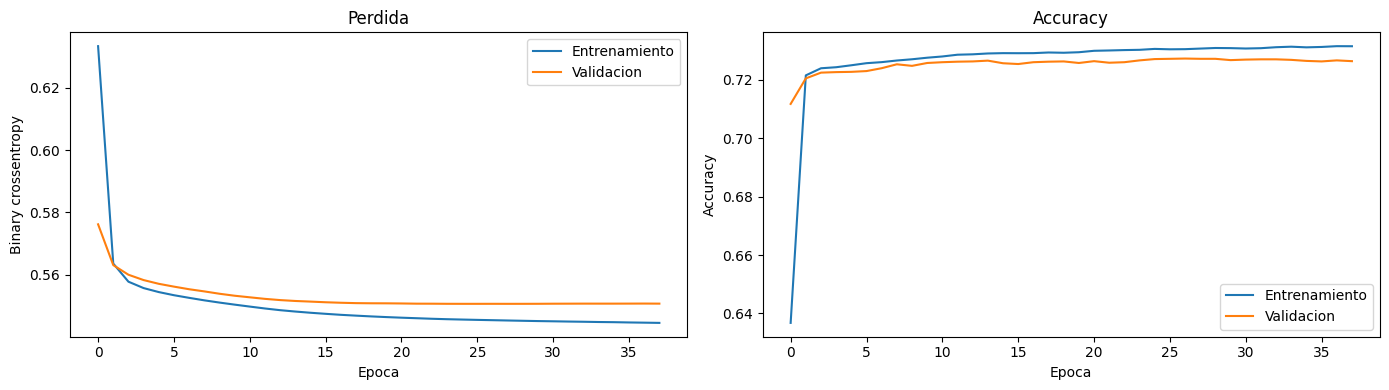

Mejor epoca: 28
Perdida minima de validacion: 0.5506
Perdida final entrenamiento: 0.5445
Perdida final validacion: 0.5507
Accuracy final entrenamiento: 0.7315
Accuracy final validacion: 0.7264


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

ejes[0].plot(historial.history["loss"], label="Entrenamiento")
ejes[0].plot(historial.history["val_loss"], label="Validacion")
ejes[0].set_title("Perdida")
ejes[0].set_xlabel("Epoca")
ejes[0].set_ylabel("Binary crossentropy")
ejes[0].legend()

ejes[1].plot(historial.history["accuracy"], label="Entrenamiento")
ejes[1].plot(historial.history["val_accuracy"], label="Validacion")
ejes[1].set_title("Accuracy")
ejes[1].set_xlabel("Epoca")
ejes[1].set_ylabel("Accuracy")
ejes[1].legend()

plt.tight_layout()
plt.show()

print("Mejor epoca:", np.argmin(historial.history["val_loss"]) + 1)
print("Perdida minima de validacion:", round(min(historial.history["val_loss"]), 4))
print("Perdida final entrenamiento:", round(historial.history["loss"][-1], 4))
print("Perdida final validacion:", round(historial.history["val_loss"][-1], 4))
print("Accuracy final entrenamiento:", round(historial.history["accuracy"][-1], 4))
print("Accuracy final validacion:", round(historial.history["val_accuracy"][-1], 4))

### 5.D Evaluación en prueba

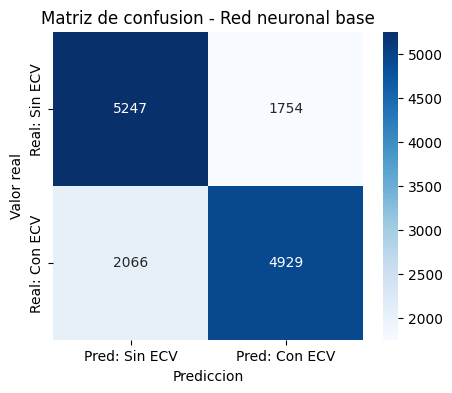

Verdaderos negativos: 5247 | Falsos positivos: 1754
Falsos negativos: 2066 | Verdaderos positivos: 4929


In [ ]:
prob_red = red_base.predict(X_test_esc, verbose=0).flatten()
pred_red = (prob_red >= 0.5).astype(int)
resultado_red = evaluar_modelo("Red neuronal base", y_test, pred_red, prob_red)

### 5.E Experimentos de mejora

* **Experimento 1 – Dropout 0.2:** apaga al azar el 20% de las neuronas en cada paso para evitar que la red memorice.
* **Experimento 2 – Arquitectura más grande:** 64 y 32 neuronas, para ver si más capacidad aprende patrones que la red base no capta.

In [ ]:
experimentos = [
    ("Red base (16-8)", 16, 8, 0.0),
    ("Exp 1: Dropout 0.2", 16, 8, 0.2),
    ("Exp 2: Red grande (64-32)", 64, 32, 0.0)
]

filas_exp = []
historiales = {}
for nombre, n1, n2, drop in experimentos:
    tf.keras.utils.set_random_seed(semilla)
    red = crear_red(n1, n2, drop)
    hist = red.fit(X_train_esc, y_train, epochs=200, batch_size=256,
                   validation_split=0.2, callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
                   verbose=0)
    historiales[nombre] = hist
    prob = red.predict(X_test_esc, verbose=0).flatten()
    pred = (prob >= 0.5).astype(int)
    filas_exp.append({
        "Experimento": nombre,
        "Epocas": len(hist.history["loss"]),
        "Perdida val. minima": min(hist.history["val_loss"]),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob)
    })

tabla_exp = pd.DataFrame(filas_exp).set_index("Experimento").round(4)
tabla_exp

,Epocas,Perdida val. minima,Accuracy,Precision,Recall,F1-score,AUC
Experimento,,,,,,,
Red base (16-8),38,0.5506,0.7271,0.7375,0.7046,0.7207,0.7967
Exp 1: Dropout 0.2,91,0.5503,0.7281,0.7374,0.7082,0.7225,0.7981
Exp 2: Red grande (64-32),20,0.5506,0.7286,0.7407,0.7032,0.7215,0.7969


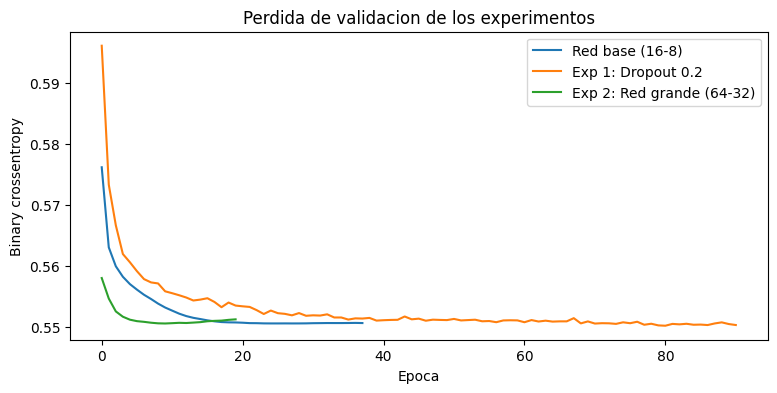

In [ ]:
plt.figure(figsize=(9, 4))
for nombre in historiales:
    plt.plot(historiales[nombre].history["val_loss"], label=nombre)
plt.title("Perdida de validacion de los experimentos")
plt.xlabel("Epoca")
plt.ylabel("Binary crossentropy")
plt.legend()
plt.show()

| Experimento | Qué cambia | Resultado |
|---|---|---|
| Red base (16-8) | — | F1 0,7207, AUC 0,7967 |
| Exp 1: Dropout 0.2 | Apaga 20% de neuronas | F1 0,7225, AUC 0,7981 (**mejor**) |
| Exp 2: Red grande (64-32) | Más neuronas | F1 0,7215, AUC 0,7969 |

**Análisis:** las dos mejoras dan resultados casi iguales a la red base; la diferencia es de milésimas. El Dropout fue el mejor por muy poco: entrenó más épocas (91) de forma más estable y llegó a la pérdida de validación más baja (0,5503). La red grande llegó a su mínimo muy rápido (época ~10) y luego la pérdida de validación empezó a subir, que es una señal leve de que empieza a memorizar; por eso el EarlyStopping la detuvo en la época 20. Conclusión: con 13 variables, más complejidad no mejora la red.

### 5.F Tabla final comparativa

                     Accuracy  Precision  Recall  F1-score    AUC
Modelo                                                           
Regresion logistica     0.720      0.746   0.666     0.704  0.790
Arbol (GridSearch)      0.724      0.740   0.691     0.715  0.794
Random Forest           0.729      0.761   0.667     0.711  0.798
Red neuronal base       0.727      0.738   0.705     0.721  0.797
Red Dropout 0.2         0.728      0.737   0.708     0.723  0.798


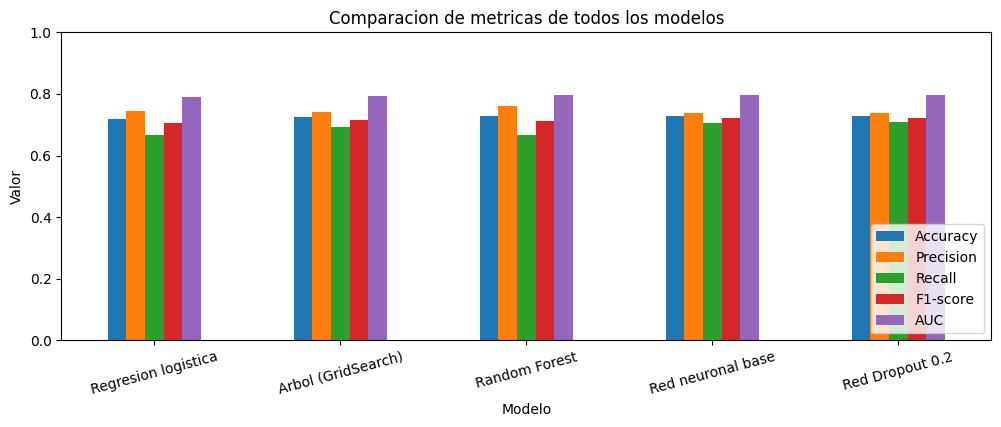

In [ ]:
#Se agrega el mejor experimento (Dropout 0.2) con las mismas metricas
fila = filas_exp[1]
resultado_drop = {"Modelo": "Red Dropout 0.2", "Accuracy": fila["Accuracy"], "Precision": fila["Precision"],
                  "Recall": fila["Recall"], "F1-score": fila["F1-score"], "AUC": fila["AUC"]}

tabla_final = pd.DataFrame([resultado_log, resultado_arbol, resultado_rf, resultado_red, resultado_drop]).set_index("Modelo").round(3)
print(tabla_final)

tabla_final.plot(kind="bar", figsize=(12, 4))
plt.title("Comparacion de metricas de todos los modelos")
plt.xlabel("Modelo")
plt.ylabel("Valor")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

**Comparación:** las redes neuronales obtienen el mejor F1 (0,721–0,723) y el mejor recall (0,705–0,708) de todos los modelos, con AUC igual al Random Forest (0,798). Pero la ventaja sobre el árbol optimizado es pequeña (F1 0,723 vs 0,715).

### Reto Bloque 5: sobreajuste o subajuste

* **No hay sobreajuste en la red base:** las curvas de entrenamiento y validación bajan juntas y se aplanan. Al final la pérdida es 0,5445 en entrenamiento y 0,5507 en validación, y el accuracy 0,7315 vs 0,7264: una diferencia muy pequeña. El EarlyStopping detuvo el entrenamiento en la época 38 y recuperó los pesos de la mejor época (28).
* **Hay un techo de desempeño (leve subajuste):** las curvas se aplanan desde la época ~15 en un accuracy cercano a 0,73, y ningún modelo pasa de ese valor. Esto indica que las 13 variables no tienen más información: no se miden cosas importantes como colesterol exacto, antecedentes familiares o electrocardiograma.
* **¿Funcionó la mejora?** El Dropout mejoró muy poco (F1 +0,002) porque la red base no estaba sobreajustando; el Dropout sirve para corregir sobreajuste y aquí no lo había. La red grande tampoco mejoró y mostró una leve señal de sobreajuste.

**¿Se justifica la complejidad de la red?** **No.** La red gana por menos de 0,01 en F1 y AUC, pero es una "caja negra", tarda más en entrenar y es difícil de explicar a un médico. El árbol de decisión da resultados casi iguales y se puede explicar con reglas sencillas.

## Bloque 6. Informe ejecutivo

**El problema.** Las enfermedades cardiovasculares son la principal causa de muerte en el mundo y muchas veces se detectan tarde. El objetivo fue construir un modelo que, con datos de una consulta médica básica (edad, sexo, estatura, peso, presión arterial, colesterol, glucosa y hábitos), identifique a los pacientes con mayor probabilidad de tener enfermedad cardiovascular, para priorizar exámenes más completos.

**Principales hallazgos.** Se analizaron cerca de 70.000 pacientes, la mitad con enfermedad cardiovascular. Los datos tenían errores de registro, como presiones negativas o de 16.000 mm Hg y estaturas de 55 cm; se corrigieron sin eliminar pacientes. El factor más relacionado con la enfermedad es la **presión arterial alta**: los pacientes enfermos tienen una presión típica de 130 frente a 120 mm Hg. Le siguen la **edad** (el porcentaje con enfermedad pasa de 24% entre los 30 y 40 años a 67% entre los 60 y 65), el **colesterol** (76% de enfermos entre quienes lo tienen muy alto, frente a 44% con colesterol normal) y el **sobrepeso**. Fumar o tomar alcohol casi no se relacionó con la enfermedad, probablemente porque son datos que el paciente declara y no siempre son verdaderos.

**Mejor modelo.** Se probaron cuatro modelos. Todos aciertan cerca del 73% de los casos y tienen un AUC cercano a 0,80, lo que indica una buena capacidad para ordenar a los pacientes por riesgo. La red neuronal fue la mejor por muy poco (encuentra 71 de cada 100 enfermos), pero se recomienda el **árbol de decisión**, que encuentra 69 de cada 100, porque se puede explicar como reglas sencillas que un médico entiende y revisa.

**Errores del modelo.** El modelo comete dos tipos de error. De cada 100 pacientes enfermos deja pasar unos 31 como sanos (falsos negativos): es el error más costoso, porque esa persona no recibe seguimiento y puede llegar a un infarto o un accidente cerebrovascular. También marca como enfermos a unos 24 de cada 100 sanos (falsos positivos): esto genera exámenes adicionales innecesarios, un costo menor pero real para la institución.

**Limitaciones.** El dataset tiene errores de digitación, no se conoce de qué país o institución provienen los pacientes y solo incluye adultos de 30 a 65 años. Faltan variables importantes, como antecedentes familiares, valores exactos de colesterol y glucosa, o un electrocardiograma. Por eso el modelo no supera el 73% de aciertos.

**Recomendaciones y trabajo futuro.** Usar el modelo como **herramienta de tamizaje** para decidir a quién remitir primero, nunca como diagnóstico. Validarlo con pacientes de la propia institución antes de usarlo, agregar las variables faltantes y revisar si conviene bajar el umbral de decisión para detectar más enfermos aunque aumenten las falsas alarmas.

**Consideraciones éticas.** Los datos de salud son sensibles: deben estar anonimizados y protegidos según la Ley 1581 de 2012 de protección de datos personales. Hay que verificar que el modelo funcione igual de bien en hombres y mujeres y en distintos grupos de edad para no discriminar a nadie. Finalmente, la decisión siempre debe ser del médico: el modelo apoya, pero no reemplaza el criterio clínico.